# Gaze-Object Baseline Video Demonstration

Render the Point-in-BBox baseline back onto a world-camera video. The default recording is selected from the existing frame-level results because it has many gaze-object hit frames.


## Setup

In [1]:
from pathlib import Path
import json

import cv2
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

DATASET_ROOT = Path("/home/julius/datasets/seminar_object_detection")
VIDEO_ROOT = DATASET_ROOT / "iAssistADL_dataset_export_2026-05-18" / "world_camera_videos"
LOWER_ROOT = DATASET_ROOT / "lower_feature_outcome"
UPPER_ROOT = DATASET_ROOT / "upper_feature_outcome"
OUTPUT_ROOT = DATASET_ROOT / "video_demostration"

GAZE_ROOT = LOWER_ROOT / "gaze_xy_filled_sensor_csv"
YOLO_ROOT = LOWER_ROOT / "yolo_object_outcome_csv"
BASELINE_ROOT = UPPER_ROOT / "gaze_object_features" / "point_in_bbox_frame_aggregation"

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

SELECTED_PARTICIPANT = "IA_4_H_14"
SELECTED_FULL_ID = "IA_4_H_14_Chaos_several_Tasks_combine1"

WINDOW_SECONDS = 30
DRAW_ALL_YOLO_BOXES = True
MAX_GAZE_POINTS_PER_FRAME = 10

video_path = VIDEO_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_world_camera.mp4"
gaze_path = GAZE_ROOT / SELECTED_PARTICIPANT / SELECTED_FULL_ID / "eye_tracker__gaze.csv"
yolo_path = YOLO_ROOT / f"{SELECTED_FULL_ID}_world_camera.csv"
frame_result_path = BASELINE_ROOT / SELECTED_PARTICIPANT / f"{SELECTED_FULL_ID}_gaze_yolo_point_in_bbox_frame.csv"
output_video_path = OUTPUT_ROOT / f"{SELECTED_FULL_ID}_gaze_object_baseline_demo.mp4"

for path in [video_path, gaze_path, yolo_path, frame_result_path]:
    assert path.exists(), f"Missing file: {path}"

video_path, gaze_path, yolo_path, frame_result_path, output_video_path


(PosixPath('/home/julius/datasets/seminar_object_detection/iAssistADL_dataset_export_2026-05-18/world_camera_videos/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_world_camera.mp4'),
 PosixPath('/home/julius/datasets/seminar_object_detection/lower_feature_outcome/gaze_xy_filled_sensor_csv/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1/eye_tracker__gaze.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/lower_feature_outcome/yolo_object_outcome_csv/IA_4_H_14_Chaos_several_Tasks_combine1_world_camera.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/upper_feature_outcome/gaze_object_features/point_in_bbox_frame_aggregation/IA_4_H_14/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_yolo_point_in_bbox_frame.csv'),
 PosixPath('/home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_baseline_demo.mp4'))

## Pick A High-Hit Window

The whole recording can be long, so this chooses the 30-second window with the most hit frames. Change `WINDOW_SECONDS` or set your own `START_FRAME` below if needed.


In [2]:
frame_result_df = pd.read_csv(frame_result_path)

cap = cv2.VideoCapture(str(video_path))
fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

if not fps or np.isnan(fps):
    fps = 30

window_frames = int(round(WINDOW_SECONDS * fps))
frame_result_df = frame_result_df.sort_values("video_frame_idx").copy()
frame_result_df["has_hit"] = frame_result_df["hit_sample_count"] > 0

rolling_hits = (
    frame_result_df.set_index("video_frame_idx")["has_hit"]
    .reindex(range(frame_count), fill_value=False)
    .astype(int)
    .rolling(window_frames, min_periods=1)
    .sum()
)

best_end_frame = int(rolling_hits.idxmax())
START_FRAME = max(0, best_end_frame - window_frames + 1)
END_FRAME = min(frame_count - 1, START_FRAME + window_frames - 1)

video_info = {
    "fps": fps,
    "frame_count": frame_count,
    "width": width,
    "height": height,
    "start_frame": START_FRAME,
    "end_frame": END_FRAME,
    "window_seconds": (END_FRAME - START_FRAME + 1) / fps,
    "hit_frames_in_window": int(rolling_hits.max()),
}
video_info


{'fps': 30.0,
 'frame_count': 3882,
 'width': 1600,
 'height': 1200,
 'start_frame': 1638,
 'end_frame': 2537,
 'window_seconds': 30.0,
 'hit_frames_in_window': 762}

## Load Gaze And YOLO Data

In [3]:
gaze_df = pd.read_csv(gaze_path)
yolo_df = pd.read_csv(yolo_path)

for col in ["video_frame_idx", "x", "y"]:
    gaze_df[col] = pd.to_numeric(gaze_df[col], errors="coerce")

yolo_numeric_cols = ["frame_id", "class_id", "confidence", "x1", "y1", "x2", "y2"]
for col in yolo_numeric_cols:
    yolo_df[col] = pd.to_numeric(yolo_df[col], errors="coerce")

gaze_df = gaze_df[np.isfinite(gaze_df["video_frame_idx"])].copy()
gaze_df["video_frame_idx"] = gaze_df["video_frame_idx"].astype(int)
yolo_df = yolo_df[np.isfinite(yolo_df["frame_id"])].copy()
yolo_df["frame_id"] = yolo_df["frame_id"].astype(int)

gaze_by_frame = {frame: df for frame, df in gaze_df.groupby("video_frame_idx")}
yolo_by_frame = {frame: df for frame, df in yolo_df.groupby("frame_id")}

print("gaze rows:", len(gaze_df))
print("yolo rows:", len(yolo_df))
print("gaze frames:", len(gaze_by_frame))
print("yolo frames:", len(yolo_by_frame))


gaze rows: 19565
yolo rows: 31786
gaze frames: 4892
yolo frames: 3858


## Rendering Helpers

In [4]:
def point_in_bbox(x, y, box):
    return box["x1"] <= x <= box["x2"] and box["y1"] <= y <= box["y2"]


def get_hit_boxes(frame_gaze, frame_yolo):
    if frame_gaze is None or frame_yolo is None or frame_gaze.empty or frame_yolo.empty:
        return []

    valid_gaze = frame_gaze[np.isfinite(frame_gaze["x"]) & np.isfinite(frame_gaze["y"])]
    if valid_gaze.empty:
        return []

    hit_boxes = []
    for detection_idx, (_, box) in enumerate(frame_yolo.iterrows()):
        hit_count = 0
        for _, gaze in valid_gaze.iterrows():
            if point_in_bbox(gaze["x"], gaze["y"], box):
                hit_count += 1
        if hit_count > 0:
            row = box.to_dict()
            row["detection_idx_in_frame"] = detection_idx
            row["hit_gaze_sample_count"] = hit_count
            row["valid_gaze_sample_count"] = len(valid_gaze)
            hit_boxes.append(row)
    return hit_boxes


def draw_label(frame, text, xy, color, font_scale=0.55, thickness=1):
    x, y = int(xy[0]), int(xy[1])
    font = cv2.FONT_HERSHEY_SIMPLEX
    (tw, th), baseline = cv2.getTextSize(text, font, font_scale, thickness)
    cv2.rectangle(frame, (x, y - th - baseline - 4), (x + tw + 6, y), color, -1)
    cv2.putText(frame, text, (x + 3, y - baseline - 2), font, font_scale, (255, 255, 255), thickness, cv2.LINE_AA)


def draw_overlay(frame, frame_idx, frame_gaze, frame_yolo):
    hit_boxes = get_hit_boxes(frame_gaze, frame_yolo)
    hit_detection_ids = {box["detection_idx_in_frame"] for box in hit_boxes}

    if DRAW_ALL_YOLO_BOXES and frame_yolo is not None:
        for detection_idx, (_, box) in enumerate(frame_yolo.iterrows()):
            x1, y1, x2, y2 = [int(round(box[c])) for c in ["x1", "y1", "x2", "y2"]]
            color = (70, 70, 70)
            thickness = 1
            if detection_idx in hit_detection_ids:
                color = (0, 220, 0)
                thickness = 3
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, thickness)

    for box in hit_boxes:
        x1, y1, x2, y2 = [int(round(box[c])) for c in ["x1", "y1", "x2", "y2"]]
        label = f"class {int(box['class_id'])} hit {int(box['hit_gaze_sample_count'])}/{int(box['valid_gaze_sample_count'])}"
        draw_label(frame, label, (x1, max(18, y1 - 4)), (0, 160, 0))

    if frame_gaze is not None and not frame_gaze.empty:
        valid_gaze = frame_gaze[np.isfinite(frame_gaze["x"]) & np.isfinite(frame_gaze["y"])]
        for _, gaze in valid_gaze.tail(MAX_GAZE_POINTS_PER_FRAME).iterrows():
            gx, gy = int(round(gaze["x"])), int(round(gaze["y"]))
            cv2.circle(frame, (gx, gy), 9, (0, 255, 255), -1)
            cv2.circle(frame, (gx, gy), 13, (0, 0, 0), 2)

    status = f"{SELECTED_FULL_ID} | frame {frame_idx} | hit boxes {len(hit_boxes)}"
    draw_label(frame, status, (12, 30), (30, 30, 30), font_scale=0.6, thickness=1)
    return frame


## Preview One Frame

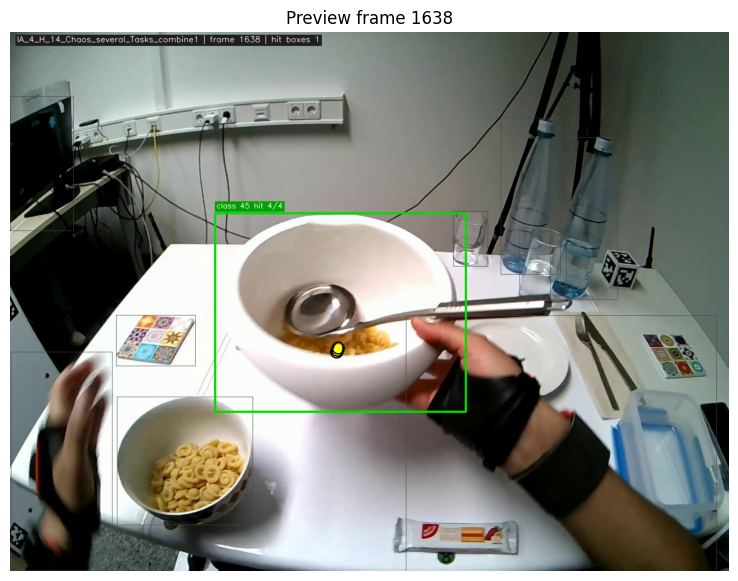

In [5]:
preview_frame_idx = START_FRAME
cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, preview_frame_idx)
ok, preview = cap.read()
cap.release()
assert ok, f"Could not read frame {preview_frame_idx}"

preview = draw_overlay(
    preview,
    preview_frame_idx,
    gaze_by_frame.get(preview_frame_idx),
    yolo_by_frame.get(preview_frame_idx),
)

preview_rgb = cv2.cvtColor(preview, cv2.COLOR_BGR2RGB)

import matplotlib.pyplot as plt
plt.figure(figsize=(12, 7))
plt.imshow(preview_rgb)
plt.axis("off")
plt.title(f"Preview frame {preview_frame_idx}")
plt.show()


## Render Demo Video

In [6]:
cap = cv2.VideoCapture(str(video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, START_FRAME)

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
writer = cv2.VideoWriter(str(output_video_path), fourcc, fps, (width, height))
assert writer.isOpened(), f"Could not open writer: {output_video_path}"

for frame_idx in tqdm(range(START_FRAME, END_FRAME + 1), desc="Rendering gaze-object demo", unit="frame"):
    ok, frame = cap.read()
    if not ok:
        print(f"Stopped early at frame {frame_idx}")
        break

    frame = draw_overlay(
        frame,
        frame_idx,
        gaze_by_frame.get(frame_idx),
        yolo_by_frame.get(frame_idx),
    )
    writer.write(frame)

writer.release()
cap.release()

print(f"Saved: {output_video_path}")


Rendering gaze-object demo:   0%|          | 0/900 [00:00<?, ?frame/s]

Saved: /home/julius/datasets/seminar_object_detection/video_demostration/IA_4_H_14_Chaos_several_Tasks_combine1_gaze_object_baseline_demo.mp4


## Optional: Inspect Hit Boxes For The Selected Window

In [7]:
hit_box_rows = []
for frame_idx in range(START_FRAME, END_FRAME + 1):
    for box in get_hit_boxes(gaze_by_frame.get(frame_idx), yolo_by_frame.get(frame_idx)):
        row = {"video_frame_idx": frame_idx}
        row.update(box)
        hit_box_rows.append(row)

hit_boxes_in_window_df = pd.DataFrame(hit_box_rows)
hit_boxes_in_window_df.head(20)


,video_frame_idx,video,frame_id,class_id,confidence,x1,y1,x2,y2,cx,cy,width,height,area,detection_idx_in_frame,hit_gaze_sample_count,valid_gaze_sample_count
0,1638,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1638,45,0.323333,455.672668,403.035431,1013.954407,845.013306,734.813538,624.024368,558.281738,441.977875,246748.176201,8,4,4
1,1642,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1642,0,0.802838,715.037720,676.692017,1484.406494,1199.582031,1099.722107,938.137024,769.368774,522.890015,402295.249723,0,4,4
2,1643,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1643,0,0.809404,688.571777,677.554565,1470.165039,1199.015259,1079.368408,938.284912,781.593262,521.460693,407570.164181,0,4,4
3,1644,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1644,0,0.822397,658.437622,682.649841,1479.169922,1198.757324,1068.803772,940.703583,820.732300,516.107483,423586.081395,0,4,4
4,1644,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1644,45,0.264217,161.210251,394.396057,773.530396,964.088867,467.370323,679.242462,612.320145,569.692810,348834.383863,5,4,4
5,1645,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1645,0,0.842246,644.418335,680.384521,1484.255859,1198.500854,1064.337097,939.442688,839.837524,518.116333,435133.538472,1,4,4
6,1645,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1645,45,0.537699,158.595337,389.578705,763.364319,969.443665,460.979828,679.511185,604.768982,579.864960,350684.341347,4,4,4
7,1646,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1646,0,0.817475,632.173523,678.227234,1486.786133,1198.554077,1059.479828,938.390656,854.612610,520.326843,444677.881502,0,4,4
8,1646,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1646,45,0.287880,136.773758,384.038696,977.021973,970.531311,556.897865,677.285004,840.248215,586.492615,492799.372488,7,4,4
9,1647,IA_4_H_14_Chaos_several_Tasks_combine1_world_c...,1647,0,0.842144,621.021606,674.625854,1490.003052,1198.456909,1055.512329,936.541382,868.981445,523.831055,455199.467002,0,4,4
